# EDA 06 · Listening logs: customer aggregates

**Question.** Which summary of listening behaviour separates churners from non-churners, over which window, and does it add anything once the subscription state (notebook 03) and the payment history (notebook 04) are known?

**Input.** Daily logs of all `fit` customers in the 90-day window, cleaned with the rule of notebook 05 (`C.clean_user_days`: days over 24 h rescaled; no quantile clipping).

**Candidates** for windows of the last 7, 14, 30 and 90 days before the cutoff:

| Group | Features |
|---|---|
| Activity | `active_days_W` |
| Volume | `secs_W`, `plays_W`, `unq_W` |
| Habit | `skip_ratio_W` (= num_25 / plays), `completion_ratio_W` (= num_100 / plays), `unq_ratio_W` (= num_unq / plays) |
| Recency | `days_since_last_log` (90 if none), `longest_gap` (longest run of silent days, including the tail up to the cutoff) |
| Trend | `trend_secs` = log1p(secs last 30 d) − log1p(secs previous 30 d), `trend_active` = active days last 30 − previous 30 |

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

EDA_DIR = next(p for p in (Path.cwd(), Path.cwd() / "eda") if (p / "_common.py").exists())
sys.path.insert(0, str(EDA_DIR))
import _common as C

pl.Config.set_tbl_rows(40); pl.Config.set_tbl_width_chars(160)
pd.options.display.float_format = "{:,.4f}".format
pd.set_option("display.max_colwidth", None)

users = C.load_fit_population()
BASE = users["is_churn"].mean()
txn = C.clean_transactions(users)
base = (C.state_block(C.subscription_state(txn, users))
        .join(C.history_block(txn, users), on="msno"))

## 1. Building the listening features

In [2]:
WINDOWS = (7, 14, 30, 90)

def build_listening():
    ud = C.clean_user_days(users)
    parts = []
    for W in WINDOWS:
        a = (ud.filter(pl.col("day") >= C.WINDOW_DAYS - W).group_by("msno").agg(
                pl.len().alias(f"active_days_{W}"), pl.col("total_secs").sum().alias(f"secs_{W}"),
                pl.col("plays").sum().alias(f"plays_{W}"), pl.col("num_unq").sum().alias(f"unq_{W}"),
                pl.col("num_25").sum().alias("_n25"), pl.col("num_100").sum().alias("_n100"))
             .with_columns((pl.col("_n25") / pl.col(f"plays_{W}")).alias(f"skip_ratio_{W}"),
                           (pl.col("_n100") / pl.col(f"plays_{W}")).alias(f"completion_ratio_{W}"),
                           (pl.col(f"unq_{W}") / pl.col(f"plays_{W}")).alias(f"unq_ratio_{W}"))
             .drop("_n25", "_n100"))
        parts.append(a)
    prev = (ud.filter(pl.col("day").is_between(C.WINDOW_DAYS - 60, C.WINDOW_DAYS - 31)).group_by("msno")
              .agg(secs_prev30=pl.col("total_secs").sum(), active_prev30=pl.len()))
    rec = (ud.group_by("msno").agg(days=pl.col("day").sort())
             .with_columns(last_day=pl.col("days").list.max(),
                           inner_gap=(pl.col("days").list.diff().list.max() - 1).fill_null(0))
             .with_columns(days_since_last_log=(C.WINDOW_DAYS - 1 - pl.col("last_day")).cast(pl.Int32),
                           longest_gap=pl.max_horizontal(pl.col("inner_gap"), C.WINDOW_DAYS - 1 - pl.col("last_day"),
                                                         pl.col("days").list.min()).cast(pl.Int32))
             .select("msno", "days_since_last_log", "longest_gap"))
    out = users.select("msno").lazy()
    for p in parts + [prev, rec]:
        out = out.join(p, on="msno", how="left")
    out = out.collect(engine="streaming")
    zero = [c for c in out.columns if c.startswith(("active_days_", "secs_", "plays_", "unq_")) and "ratio" not in c] + ["active_prev30"]
    out = out.with_columns(
        has_logs=pl.col("days_since_last_log").is_not_null().cast(pl.Int8),
        *[pl.col(c).fill_null(0) for c in zero],
        days_since_last_log=pl.col("days_since_last_log").fill_null(C.WINDOW_DAYS),
        longest_gap=pl.col("longest_gap").fill_null(C.WINDOW_DAYS))
    return out.with_columns(
        trend_secs=(pl.col("secs_30").log1p() - pl.col("secs_prev30").log1p()),
        trend_active=(pl.col("active_days_30").cast(pl.Int32) - pl.col("active_prev30").cast(pl.Int32)),
    ).drop("secs_prev30", "active_prev30")

lis = C.cached("06_listening_features", build_listening)
LIS = [c for c in lis.columns if c != "msno"]
df = base.join(lis, on="msno")
print(f"customers: {df.height:,} | listening features: {len(LIS)} | with logs: {df['has_logs'].mean():.1%}")
df.select(["active_days_30", "secs_30", "skip_ratio_90", "completion_ratio_90", "unq_ratio_90",
           "days_since_last_log", "longest_gap", "trend_secs", "trend_active"]).describe()

customers: 744,699 | listening features: 33 | with logs: 81.4%


statistic,active_days_30,secs_30,skip_ratio_90,completion_ratio_90,unq_ratio_90,days_since_last_log,longest_gap,trend_secs,trend_active
str,f64,f64,f64,f64,f64,f64,f64,f64,f64
"""count""",744699.0,744699.0,605922.0,605922.0,605922.0,744699.0,744699.0,744699.0,744699.0
"""null_count""",0.0,0.0,138777.0,138777.0,138777.0,0.0,0.0,0.0,0.0
"""mean""",13.307555,105311.501511,0.196958,0.688696,0.765206,20.341946,30.013639,0.343808,0.256904
"""std""",10.702271,159413.587677,0.150485,0.199881,0.163535,34.86481,33.994529,2.667267,5.277636
"""min""",0.0,0.0,0.0,0.0,0.002992,0.0,0.0,-14.071972,-30.0
"""25%""",2.0,2324.246,0.090583,0.581633,0.689066,0.0,4.0,-0.275607,-2.0
"""50%""",13.0,51875.361,0.163265,0.725258,0.804054,1.0,11.0,0.0,0.0
"""75%""",23.0,140085.614,0.263158,0.837373,0.881923,14.0,55.0,0.352509,2.0
"""max""",30.0,2.5692e6,1.0,1.0,1.0,90.0,90.0,14.643335,30.0


## 2. Each candidate against churn

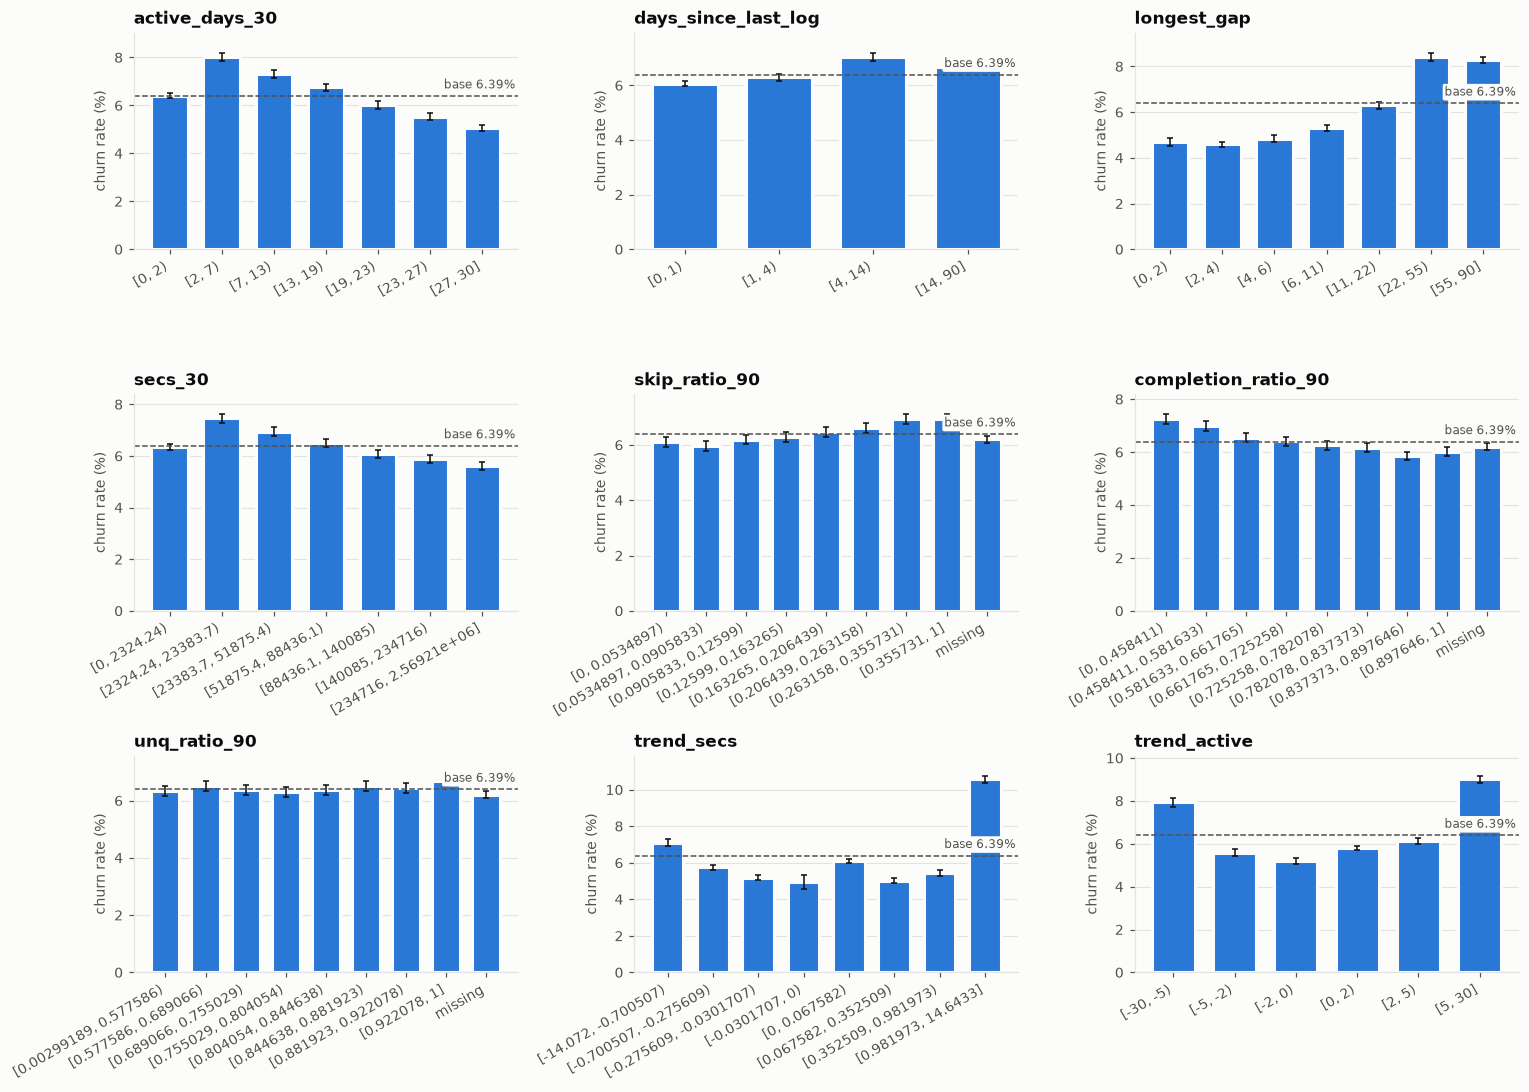

In [3]:
SHOW = ["active_days_30", "days_since_last_log", "longest_gap", "secs_30", "skip_ratio_90",
        "completion_ratio_90", "unq_ratio_90", "trend_secs", "trend_active"]
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.ravel(), SHOW):
    binned = C.quantile_bins(df, col, q=8)
    tbl = C.churn_rate_by(binned, f"{col}_bin")
    tbl["_lo"] = pd.to_numeric(tbl[f"{col}_bin"].str.extract(r"\[(-?[\d.e+-]+)")[0], errors="coerce")
    tbl = tbl.sort_values("_lo", na_position="last").reset_index(drop=True)
    C.plot_churn_rate(tbl, f"{col}_bin", ax=ax, base_rate=BASE, title=col, rotate=30, show_n=False)
    ax.set_xlabel("")
fig.tight_layout(); C.save_fig(fig, "06_listening_univariate"); plt.show()


On the whole population every listening feature is weak: churn stays between about 4.5 % and 10 % across all bins. The clearest raw patterns are a long silent gap (22+ days: about 8 %), a falling month (`trend_active` below −5: 8 %) and, unexpectedly, a **sharp rise** in listening (top `trend_secs` bin: 10.5 %, top `trend_active` bin: 9 %). The rise is most likely recent sign-ups and trial users ramping up, who churn more for reasons notebooks 01 and 03 already capture (new tenure, free last payment). Skip, completion and unique-song ratios are close to flat. The weakness is a composition effect: 87 % of customers auto-renew and keep paying whether they listen or not.


## 3. Inside the subscription state

In [4]:
def within(col, edges, labels):
    expr = pl.when(pl.col(col) <= edges[0]).then(pl.lit(labels[0]))
    for e, l in zip(edges[1:], labels[1:]):
        expr = expr.when(pl.col(col) <= e).then(pl.lit(l))
    expr = expr.otherwise(pl.lit(labels[-1]))
    d = df.filter(pl.col("state").is_in(["auto-renew", "manual"])).with_columns(band=expr)
    t = C.churn_rate_by(d, ["band", "state"])
    p = t.pivot(index="band", columns="state", values="churn_rate").reindex(labels)
    n = t.pivot(index="band", columns="state", values="n").reindex(labels)
    return p.join(n, rsuffix=" n")

tables = {
    "days_since_last_log": within("days_since_last_log", [0, 3, 7, 14, 30, 89], ["0", "1-3", "4-7", "8-14", "15-30", "31-89", "no logs (90)"]),
    "active_days_30": within("active_days_30", [0, 5, 15, 25], ["0", "1-5", "6-15", "16-25", "26-30"]),
    "trend_secs (logs only)": None,
}
d = df.filter((pl.col("has_logs") == 1) & pl.col("state").is_in(["auto-renew", "manual"])).with_columns(
    band=pl.when(pl.col("trend_secs") <= -2).then(pl.lit("strong drop")).when(pl.col("trend_secs") <= -0.5).then(pl.lit("drop"))
    .when(pl.col("trend_secs") < 0.5).then(pl.lit("stable")).when(pl.col("trend_secs") < 2).then(pl.lit("rise")).otherwise(pl.lit("strong rise")))
t = C.churn_rate_by(d, ["band", "state"]); order = ["strong drop", "drop", "stable", "rise", "strong rise"]
tables["trend_secs (logs only)"] = t.pivot(index="band", columns="state", values="churn_rate").reindex(order).join(
    t.pivot(index="band", columns="state", values="n").reindex(order), rsuffix=" n")
for name, tbl in tables.items():
    print(f"\n{name}"); print(tbl.to_string(float_format=lambda v: f"{v:,.4f}"))


days_since_last_log
state         auto-renew  manual  auto-renew n  manual n
band                                                    
0                 0.0153  0.2716        251208     52181
1-3               0.0184  0.3349        130725     20108
4-7               0.0222  0.4082         60523      6659
8-14              0.0253  0.5535         27834      2020
15-30             0.0316  0.6745         21446       897
31-89             0.0332  0.8029         22530       416
no logs (90)      0.0312  0.8753        132892       802

active_days_30
state  auto-renew  manual  auto-renew n  manual n
band                                             
0          0.0315  0.8479        156459      1236
1-5        0.0254  0.5783         80128      6867
6-15       0.0206  0.3836        136299     20071
16-25      0.0164  0.2738        160000     30011
26-30      0.0129  0.2188        114272     24898

trend_secs (logs only)
state        auto-renew  manual  auto-renew n  manual n
band                


- Inside **manual** payment, listening is a strong signal. Churn goes from 27 % for customers who listened on the last day to 55 % after 8–14 silent days, 80 % after a month, and **88 % with no listening in 90 days**. By active days in the last month: 22 % (26–30 days) up to 85 % (none). A manual customer has to decide to pay again, and one who has stopped listening rarely does.
- Inside **auto-renew** the same gradient exists but is compressed: 1.5 % (listened today) to 3.1–3.3 % (silent for weeks or never). Small in absolute terms, it still doubles the risk inside the largest group.
- Trend works the same way: in the manual group a strong drop goes with 60 % churn against 25 % for a stable month (and a strong rise with 48 %, the new-customer effect above).


## 4. Redundancy

In [5]:
sample = df.filter(pl.col("has_logs") == 1).select(LIS).sample(n=200_000, seed=C.SEED).to_pandas()
rho = sample.corr(method="spearman")
pairs = (rho.where(np.triu(np.ones(rho.shape, dtype=bool), k=1)).stack().rename("spearman").reset_index()
           .rename(columns={"level_0": "a", "level_1": "b"}))
pairs = pairs.reindex(pairs.spearman.abs().sort_values(ascending=False).index)
print(f"pairs with |rho| >= 0.9: {(pairs.spearman.abs() >= 0.9).sum()} of {len(pairs)}")
pairs[pairs.spearman.abs() >= 0.9].head(25).reset_index(drop=True)

pairs with |rho| >= 0.9: 34 of 1089


,a,b,spearman
0,secs_90,plays_90,0.9843
1,secs_7,plays_7,0.9835
2,secs_30,plays_30,0.9835
3,secs_14,plays_14,0.9829
4,plays_90,unq_90,0.9732
5,plays_7,unq_7,0.9715
6,plays_30,unq_30,0.9700
7,plays_14,unq_14,0.9694
8,secs_90,unq_90,0.9553
9,secs_7,unq_7,0.9540


## 5. What does listening add on top of state + history? (5-fold CV, gradient boosting)

Base model: the notebook-03 state block (categorical) plus the four notebook-04 history features. Listening blocks are added one at a time.

In [6]:
y = df["is_churn"].to_numpy()
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=C.SEED)
data = df.to_pandas()

def gbm(num, cat):
    pre = ColumnTransformer([("num", "passthrough", list(num)),
                             ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat))])
    return make_pipeline(pre, HistGradientBoostingClassifier(max_iter=300, learning_rate=0.08, random_state=C.SEED))

def cv(extra, base_num=C.HISTORY_BLOCK, cat=C.STATE_BLOCK):
    num = list(base_num) + list(extra)
    s = cross_validate(gbm(num, cat), data[num + list(cat)], y, cv=CV,
                       scoring=("roc_auc", "average_precision", "neg_log_loss"), n_jobs=5)
    return {"roc_auc": s["test_roc_auc"].mean(), "avg_precision": s["test_average_precision"].mean(),
            "log_loss": -s["test_neg_log_loss"].mean(), "n_listening": len(extra)}

def block(W):
    return [f"active_days_{W}", f"secs_{W}", f"plays_{W}", f"unq_{W}",
            f"skip_ratio_{W}", f"completion_ratio_{W}", f"unq_ratio_{W}"]

RECENCY = ["has_logs", "days_since_last_log", "longest_gap"]
TREND = ["trend_secs", "trend_active"]
runs = {"state + history (base)": []}
runs["+ recency"] = RECENCY
for W in WINDOWS:
    runs[f"+ window {W} d"] = block(W)
runs["+ trend"] = TREND
runs["+ all listening"] = LIS
res = pd.DataFrame({k: cv(v) for k, v in runs.items()}).T
res["d_auc"] = res["roc_auc"] - res.loc["state + history (base)", "roc_auc"]
res["d_ap"] = res["avg_precision"] - res.loc["state + history (base)", "avg_precision"]
res

,roc_auc,avg_precision,log_loss,n_listening,d_auc,d_ap
state + history (base),0.8930,0.5655,0.1468,0.0000,0.0000,0.0000
+ recency,0.8997,0.5935,0.1425,3.0000,0.0067,0.0280
+ window 7 d,0.8984,0.5861,0.1438,7.0000,0.0054,0.0207
+ window 14 d,0.8987,0.5897,0.1433,7.0000,0.0058,0.0242
+ window 30 d,0.8986,0.5917,0.1430,7.0000,0.0057,0.0262
+ window 90 d,0.8980,0.5910,0.1433,7.0000,0.0051,0.0255
+ trend,0.8978,0.5879,0.1436,2.0000,0.0049,0.0225
+ all listening,0.8991,0.5947,0.1426,33.0000,0.0061,0.0293



- Listening adds about +0.006 AUC and **+0.028 AP** on top of state + history. That is modest next to the state (AUC 0.81 alone) and history (+0.036), but it is the only block that sees *usage*.
- **Recency alone** (`has_logs`, `days_since_last_log`, `longest_gap`) captures almost all of it: +0.0067 AUC and +0.028 AP with 3 features, against +0.029 AP with all 33.
- The window length barely matters once a volume block is present (7, 14, 30 and 90 days within 0.006 AP of each other; 30 days is marginally best).
- Redundancy is massive: seconds, plays and unique songs are the same quantity (ρ 0.95–0.98) and adjacent windows overlap (ρ 0.92–0.94).


In [7]:
SHORT = ["has_logs", "days_since_last_log", "longest_gap", "active_days_30", "secs_30"]
extra = pd.DataFrame({"+ short list (5)": cv(SHORT)}).T
extra["d_auc"] = extra["roc_auc"] - res.loc["state + history (base)", "roc_auc"]
extra["d_ap"] = extra["avg_precision"] - res.loc["state + history (base)", "avg_precision"]
pd.concat([res, extra])

,roc_auc,avg_precision,log_loss,n_listening,d_auc,d_ap
state + history (base),0.8930,0.5655,0.1468,0.0000,0.0000,0.0000
+ recency,0.8997,0.5935,0.1425,3.0000,0.0067,0.0280
+ window 7 d,0.8984,0.5861,0.1438,7.0000,0.0054,0.0207
+ window 14 d,0.8987,0.5897,0.1433,7.0000,0.0058,0.0242
+ window 30 d,0.8986,0.5917,0.1430,7.0000,0.0057,0.0262
+ window 90 d,0.8980,0.5910,0.1433,7.0000,0.0051,0.0255
+ trend,0.8978,0.5879,0.1436,2.0000,0.0049,0.0225
+ all listening,0.8991,0.5947,0.1426,33.0000,0.0061,0.0293
+ short list (5),0.8997,0.5960,0.1423,5.0000,0.0067,0.0305


## 6. Conclusions


- Listening is weak on its own because most customers auto-renew regardless of use. It becomes strong **inside the manual-payment group**, where silence predicts that the customer will not come back to pay.
- Five features keep the whole listening contribution (AUC 0.8997, AP 0.596, the same as all 33): `has_logs`, `days_since_last_log`, `longest_gap`, `active_days_30`, `secs_30`.
- They replace the current w1 monthly blocks (last / second / third active month sums, means, ratios and `trend_*`). The monthly design ranks *active months*, not calendar windows, so a customer silent for two months still gets a "last month" from an older period, which hides recency.
- Recency is also the strongest argument for w2's daily sequences: notebook 07 checks whether the timing of the silence matters beyond these summaries.


In [8]:
decisions = C.write_decisions("06", "Listening logs: customer aggregates", [
    {"finding": "Raw listening features are weak (4.5-10 % churn across bins) because 87 % auto-renew regardless of use",
     "decision": "Never evaluate listening features alone; always next to `state`",
     "kind": "no action"},
    {"finding": "Inside manual payment, silence is strong: 27 % (listened on the last day) to 88 % (no logs in 90 days)",
     "decision": "Linear model: interact recency bands with `state` (manual vs rest); trees find it alone",
     "kind": "transformation"},
    {"finding": "Recency (has_logs, days_since_last_log, longest_gap) gives +0.028 AP alone; 5 features match all 33 (AP 0.596)",
     "decision": "Keep `has_logs`, `days_since_last_log` (90 if none), `longest_gap`, `active_days_30`, `secs_30` (log1p for linear)",
     "kind": "new feature"},
    {"finding": "secs / plays / unique songs are the same quantity (rho 0.95-0.98); adjacent windows overlap (0.92-0.94)",
     "decision": "One volume measure (`secs_30`) and one window (30 days)",
     "kind": "drop"},
    {"finding": "Skip, completion and unique-song ratios are flat against churn",
     "decision": "Drop the ratio features (`ratio_25`, `ratio_100`, `trend_ratio*` in w1)",
     "kind": "drop"},
    {"finding": "A sharp rise in listening goes with more churn (new / trial customers ramping up)",
     "decision": "Drop `trend_*`; the effect is covered by tenure and free last payment",
     "kind": "drop"},
    {"finding": "Current w1 monthly blocks rank active months, not calendar windows, hiding recency",
     "decision": "Replace the w1 monthly listening blocks (last / second / third month sums, means, logins, login_difference) with the 5 features above",
     "kind": "drop"},
])
decisions

,finding,decision,kind
0,Raw listening features are weak (4.5-10 % churn across bins) because 87 % auto-renew regardless of use,Never evaluate listening features alone; always next to `state`,no action
1,"Inside manual payment, silence is strong: 27 % (listened on the last day) to 88 % (no logs in 90 days)",Linear model: interact recency bands with `state` (manual vs rest); trees find it alone,transformation
2,"Recency (has_logs, days_since_last_log, longest_gap) gives +0.028 AP alone; 5 features match all 33 (AP 0.596)","Keep `has_logs`, `days_since_last_log` (90 if none), `longest_gap`, `active_days_30`, `secs_30` (log1p for linear)",new feature
3,secs / plays / unique songs are the same quantity (rho 0.95-0.98); adjacent windows overlap (0.92-0.94),One volume measure (`secs_30`) and one window (30 days),drop
4,"Skip, completion and unique-song ratios are flat against churn","Drop the ratio features (`ratio_25`, `ratio_100`, `trend_ratio*` in w1)",drop
5,A sharp rise in listening goes with more churn (new / trial customers ramping up),Drop `trend_*`; the effect is covered by tenure and free last payment,drop
6,"Current w1 monthly blocks rank active months, not calendar windows, hiding recency","Replace the w1 monthly listening blocks (last / second / third month sums, means, logins, login_difference) with the 5 features above",drop


---
**Previous:** `05_user_logs_quality.ipynb` · **Next:** `07_trajectories.ipynb`